## Restaurant Sales dataset with 100 records, designed for data cleaning, visualization, and insights.


## dataset column name and its description

| Column         | Description                                               |
| -------------- | --------------------------------------------------------- |
| Order_ID       | Unique order number                                       |
| Order_Date     | Date of order                                             |
| Restaurant     | Restaurant name                                           |
| Cuisine        | South Indian, North Indian, Chinese, Italian, Continental |
| Item           | Food item ordered                                         |
| Quantity       | Number of items ordered                                   |
| Unit_Price     | Price of one item                                         |
| Total_Amount   | Quantity × Unit Price                                     |
| Payment_Method | UPI, Card, Cash, Net Banking                              |
| City           | Customer/order city                                       |
| Rating         | Customer rating from 2.5 to 5                             |

## 1. Importing Neccessary Libraries

In [43]:
# import libraries

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [44]:
# import the Restaurant dataset

restaurant_dataset = pd.read_csv("restaurant_sales_raw.csv")

In [45]:
restaurant_dataset

,Order_ID,Order_Date,Restaurant,Cuisine,Item,Quantity,Unit_Price,Total_Amount,Payment_Method,City,Rating
0,R001,2026-08-04,Dindigul Thalappakatti,continental,Grilled Chicken,3.0,150.0,NaN,UPI,Coimbatore,NaN
1,R002,2026-08-08,KFC,Continental,Grilled Chicken,NaN,NaN,400.0,NaN,chennai,4.8
2,R003,2026-09-04,Anand Bhavan,Italian,Garlic Bread,NaN,200.0,NaN,Card,Trichy,3.4
3,R004,2026-09-01,Domino's,South Indian,Dosa,3.0,NaN,180.0,Net Banking,Chennai,4.4
4,R005,2026-08-04,Dindigul Thalappakatti,continental,Sandwich,2.0,220.0,NaN,Card,chennai,NaN
...,...,...,...,...,...,...,...,...,...,...,...
98,R099,2026-08-29,Sangeetha,italian,Pizza,NaN,150.0,300.0,Card,Coimbatore,4.7
99,R100,2026-09-02,Anand Bhavan,North Indian,Biryani,4.0,250.0,1000.0,UPI,Chennai,NaN
100,R004,2026-09-01,Domino's,South Indian,Dosa,3.0,NaN,180.0,Net Banking,Chennai,4.4
101,R018,2026-08-25,Dindigul Thalappakatti,italian,Pasta,NaN,200.0,400.0,Net Banking,Trichy,3.5


In [46]:
restaurant_dataset.shape

(103, 11)

In [47]:
restaurant_dataset.describe()

,Quantity,Unit_Price,Total_Amount,Rating
count,71.000000,72.000000,61.000000,65.000000
mean,2.352113,170.694444,365.245902,3.798462
std,1.043327,67.036387,229.743383,0.717307
min,1.000000,60.000000,60.000000,2.500000
25%,1.500000,120.000000,200.000000,3.100000
50%,2.000000,150.000000,300.000000,3.800000
75%,3.000000,220.000000,450.000000,4.400000
max,4.000000,300.000000,1200.000000,5.000000


In [48]:
restaurant_dataset.dtypes

Order_ID           object
Order_Date         object
Restaurant         object
Cuisine            object
Item               object
Quantity          float64
Unit_Price        float64
Total_Amount      float64
Payment_Method     object
City               object
Rating            float64
dtype: object

## 2. Data cleaning

In [49]:
# renaming the column name Restaurant to restaurant name

restaurant_dataset.rename(columns={"Restaurant": "restaurant_name"},inplace=True)

In [50]:
restaurant_dataset.columns

Index(['Order_ID', 'Order_Date', 'restaurant_name', 'Cuisine', 'Item',
       'Quantity', 'Unit_Price', 'Total_Amount', 'Payment_Method', 'City',
       'Rating'],
      dtype='object')

In [51]:
# checking null value count in the column
restaurant_dataset.isnull().sum()

Order_ID            0
Order_Date          0
restaurant_name     0
Cuisine             0
Item                0
Quantity           32
Unit_Price         31
Total_Amount       42
Payment_Method     18
City                0
Rating             38
dtype: int64

In [52]:
# finding the duplicate rows

restaurant_dataset.duplicated()  # here the duplicated rows will be true

0      False
1      False
2      False
3      False
4      False
       ...  
98     False
99     False
100     True
101     True
102     True
Length: 103, dtype: bool

In [53]:
#finding the count of the duplicated row

restaurant_dataset.duplicated().sum()  # 3 rows are duplicated

np.int64(3)

In [54]:
# droping duplicates from the dataset

restaurant_dataset=restaurant_dataset.drop_duplicates()

In [14]:
restaurant_dataset.shape  # 3 rows are dropped

(100, 11)

In [55]:
# standardize the column name
#  by making the first letter capital and other small

restaurant_dataset.columns = restaurant_dataset.columns.str.capitalize()


In [56]:
# converting the datatypes

restaurant_dataset["Order_date"] = pd.to_datetime(restaurant_dataset["Order_date"])
restaurant_dataset["Quantity"] = pd.to_numeric(restaurant_dataset["Quantity"])
restaurant_dataset["Quantity"] = pd.to_numeric(restaurant_dataset["Quantity"], errors="coerce")   # errors = "coerce" replaces non converted values to Nan or NAT
restaurant_dataset["Unit_price"] = pd.to_numeric(restaurant_dataset["Unit_price"], errors="coerce")
restaurant_dataset["Total_amount"] = pd.to_numeric(restaurant_dataset["Total_amount"], errors="coerce")
restaurant_dataset["Rating"] = pd.to_numeric(restaurant_dataset["Rating"], errors="coerce")

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/3850889930.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset["Order_date"] = pd.to_datetime(restaurant_dataset["Order_date"])
/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/3850889930.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset["Quantity"] = pd.to_numeric(restaurant_dataset["Quantity"])
/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/3850889930.py:5: SettingWithCop

In [57]:
restaurant_dataset.dtypes

Order_id                   object
Order_date         datetime64[ns]
Restaurant_name            object
Cuisine                    object
Item                       object
Quantity                  float64
Unit_price                float64
Total_amount              float64
Payment_method             object
City                       object
Rating                    float64
dtype: object

## Mean,Median,Mode

1.Mean - when the column is numerical (eg: 100,200,300)and it does not have extreme outliers(eg: 100,200,300,10000) , 
         then we should go for Mean

2.median - when the column  is numerical and it has outliers (eg: 100,200,300,10000) , 
         then we should go for median

3.mode - when the column is text values (categorical)(eg:places=["india","london","dublin","sweden"]) then go for mode



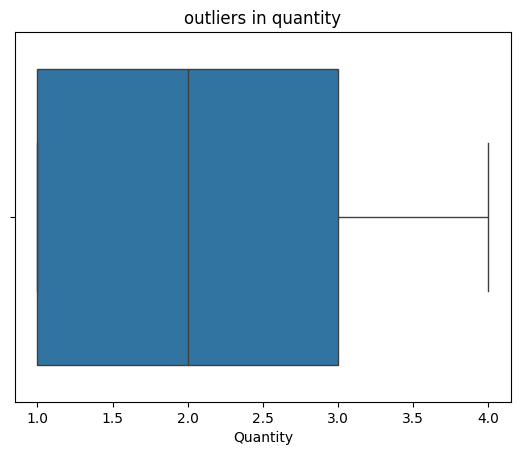

In [58]:
sns.boxplot(x=restaurant_dataset["Quantity"])
plt.title("outliers in quantity")
plt.show()

In [59]:
Q1 = restaurant_dataset['Quantity'].quantile(0.25)
print(f"q1:{Q1}")
Q3 = restaurant_dataset['Quantity'].quantile(0.75)
print(f"q3:{Q3}")
IQR = Q3 - Q1

outliers = restaurant_dataset[(restaurant_dataset['Quantity'] < Q1 - 1.5 * IQR) | (restaurant_dataset['Quantity'] > Q3 + 1.5 * IQR)]

print(outliers["Quantity"])

q1:1.0
q3:3.0
Series([], Name: Quantity, dtype: float64)


In [60]:
# filling missing value
# Quantity           32
# Unit_Price         31
# Total_Amount       42
# Payment_Method     18
# City                0
# Rating             38



restaurant_dataset['Quantity'] = restaurant_dataset['Quantity'].fillna(restaurant_dataset['Quantity'].median())

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/3656652851.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset['Quantity'] = restaurant_dataset['Quantity'].fillna(restaurant_dataset['Quantity'].median())


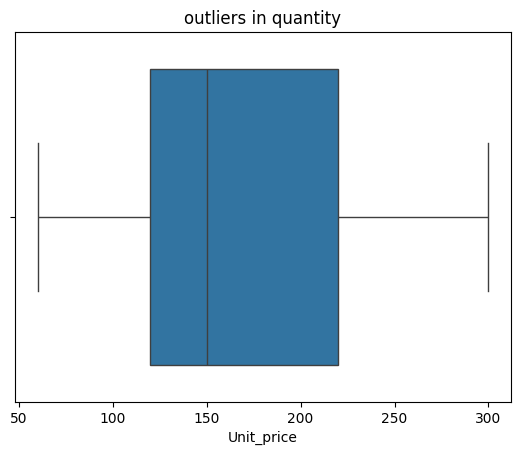

In [61]:
sns.boxplot(x=restaurant_dataset["Unit_price"])
plt.title("outliers in quantity")
plt.show()

In [62]:
Q1 = restaurant_dataset['Unit_price'].quantile(0.25)
print(f"q1:{Q1}")
Q3 = restaurant_dataset['Unit_price'].quantile(0.75)
print(f"q3:{Q3}")
IQR = Q3 - Q1

outliers = restaurant_dataset[(restaurant_dataset['Unit_price'] < Q1 - 1.5 * IQR) | (restaurant_dataset['Unit_price'] > Q3 + 1.5 * IQR)]

print(outliers['Unit_price'])

q1:120.0
q3:220.0
Series([], Name: Unit_price, dtype: float64)


In [63]:
restaurant_dataset['Unit_price'] = restaurant_dataset['Unit_price'].fillna(restaurant_dataset['Unit_price'].median())

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/2928520091.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset['Unit_price'] = restaurant_dataset['Unit_price'].fillna(restaurant_dataset['Unit_price'].median())


In [64]:
# Total amount for the food order is calculated by Total_amount = Quantity * Unit_price

restaurant_dataset['Total_amount'] = restaurant_dataset['Quantity'] * restaurant_dataset['Unit_price']

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/3690096504.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset['Total_amount'] = restaurant_dataset['Quantity'] * restaurant_dataset['Unit_price']


In [65]:
restaurant_dataset['Total_amount']

0      450.0
1      300.0
2      400.0
3      450.0
4      440.0
       ...  
95     300.0
96     240.0
97     100.0
98     300.0
99    1000.0
Name: Total_amount, Length: 100, dtype: float64

In [66]:
# FILLING MISSING CATEGORICAL VALUES

restaurant_dataset["Payment_method"] = restaurant_dataset["Payment_method"].fillna("Unknown")

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/2032462845.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset["Payment_method"] = restaurant_dataset["Payment_method"].fillna("Unknown")


In [67]:
restaurant_dataset['Payment_method'].values

array(['UPI', 'Unknown', 'Card', 'Net Banking', 'Card', 'Net Banking',
       'Cash', 'Unknown', 'Cash', 'Card', 'Net Banking', 'UPI', 'Cash',
       'Cash', 'Card', 'Card', 'Cash', 'Net Banking', 'UPI', 'Cash',
       'UPI', 'Cash', 'Net Banking', 'Unknown', 'Card', 'Unknown', 'Card',
       'Unknown', 'Unknown', 'Card', 'Cash', 'Net Banking', 'UPI',
       'Net Banking', 'Unknown', 'Card', 'Card', 'Unknown', 'Net Banking',
       'UPI', 'UPI', 'Net Banking', 'Card', 'Unknown', 'Net Banking',
       'UPI', 'Net Banking', 'Unknown', 'Card', 'Cash', 'UPI', 'Cash',
       'UPI', 'UPI', 'Cash', 'UPI', 'Unknown', 'Card', 'Unknown',
       'Unknown', 'Card', 'Cash', 'Card', 'UPI', 'Net Banking', 'Card',
       'Card', 'Unknown', 'Card', 'Unknown', 'Cash', 'UPI', 'UPI', 'Cash',
       'Net Banking', 'Unknown', 'Card', 'Unknown', 'Card', 'Card',
       'Card', 'Card', 'Card', 'UPI', 'UPI', 'Net Banking', 'Cash', 'UPI',
       'Net Banking', 'UPI', 'Cash', 'Net Banking', 'Cash', 'Net Banking',

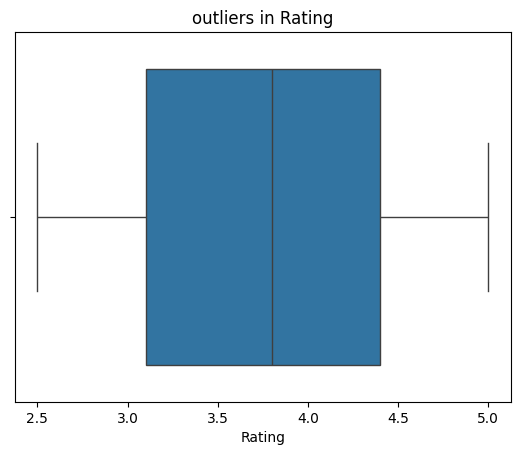

In [68]:
sns.boxplot(x=restaurant_dataset["Rating"])
plt.title("outliers in Rating")
plt.show()

In [69]:
restaurant_dataset['Rating'] = restaurant_dataset['Rating'].fillna(restaurant_dataset['Rating'].median())

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/657062717.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  restaurant_dataset['Rating'] = restaurant_dataset['Rating'].fillna(restaurant_dataset['Rating'].median())


In [70]:
# Missing values after cleaning

restaurant_dataset.isnull().sum()

Order_id           0
Order_date         0
Restaurant_name    0
Cuisine            0
Item               0
Quantity           0
Unit_price         0
Total_amount       0
Payment_method     0
City               0
Rating             0
dtype: int64

In [71]:
## The restaurant data is cleaned.

restaurant_dataset_cleaned = restaurant_dataset.copy()

In [38]:
restaurant_dataset_cleaned

,Order_id,Order_date,Restaurant_name,Cuisine,Item,Quantity,Unit_price,Total_amount,Payment_method,City,Rating
0,R001,2026-08-04,Dindigul Thalappakatti,continental,Grilled Chicken,3.0,150.0,450.0,UPI,Coimbatore,3.8
1,R002,2026-08-08,KFC,Continental,Grilled Chicken,2.0,150.0,300.0,Unknown,chennai,4.8
2,R003,2026-09-04,Anand Bhavan,Italian,Garlic Bread,2.0,200.0,400.0,Card,Trichy,3.4
3,R004,2026-09-01,Domino's,South Indian,Dosa,3.0,150.0,450.0,Net Banking,Chennai,4.4
4,R005,2026-08-04,Dindigul Thalappakatti,continental,Sandwich,2.0,220.0,440.0,Card,chennai,3.8
...,...,...,...,...,...,...,...,...,...,...,...
95,R096,2026-09-21,Hotel Saravana,CHINESE,Fried Rice,2.0,150.0,300.0,Card,Chennai,3.8
96,R097,2026-09-20,Hotel Saravana,South Indian,Idli,4.0,60.0,240.0,Net Banking,CHENNAI,3.8
97,R098,2026-09-05,Anand Bhavan,Continental,Grilled Chicken,1.0,100.0,100.0,Cash,Coimbatore,2.5
98,R099,2026-08-29,Sangeetha,italian,Pizza,2.0,150.0,300.0,Card,Coimbatore,4.7


In [39]:
restaurant_dataset_cleaned.to_csv("restaurant_dataset_cleaned",index=False)

## 3. Data visualization

In [75]:
restaurant_dataset_cleaned.head(5)

,Order_id,Order_date,Restaurant_name,Cuisine,Item,Quantity,Unit_price,Total_amount,Payment_method,City,Rating
0,R001,2026-08-04,Dindigul Thalappakatti,continental,Grilled Chicken,3.0,150.0,450.0,UPI,Coimbatore,3.8
1,R002,2026-08-08,KFC,Continental,Grilled Chicken,2.0,150.0,300.0,Unknown,chennai,4.8
2,R003,2026-09-04,Anand Bhavan,Italian,Garlic Bread,2.0,200.0,400.0,Card,Trichy,3.4
3,R004,2026-09-01,Domino's,South Indian,Dosa,3.0,150.0,450.0,Net Banking,Chennai,4.4
4,R005,2026-08-04,Dindigul Thalappakatti,continental,Sandwich,2.0,220.0,440.0,Card,chennai,3.8


## Columns and its data type (Discrete or continuous)

Order_ID -  Discrete

Order_Date - Discrete

Restaurant	- Discrete(categorical)

Cuisine	- Discrete(categorical)

Item - Discrete(categorical)

Quantity - 	Discrete

Unit_Price - Continuous

Total_Amount - Continuous 

Payment_Method- Discrete(categorical)

City - Discrete(categorical)

Customer rating - Continuous 


In [105]:
restaurant_cleaned_data = pd.read_csv("restaurant_dataset_cleaned")
restaurant_cleaned_data

,Order_id,Order_date,Restaurant_name,Cuisine,Item,Quantity,Unit_price,Total_amount,Payment_method,City,Rating
0,R001,2026-08-04,Dindigul Thalappakatti,continental,Grilled Chicken,3.0,150.0,450.0,UPI,Coimbatore,3.8
1,R002,2026-08-08,KFC,Continental,Grilled Chicken,2.0,150.0,300.0,Unknown,chennai,4.8
2,R003,2026-09-04,Anand Bhavan,Italian,Garlic Bread,2.0,200.0,400.0,Card,Trichy,3.4
3,R004,2026-09-01,Domino's,South Indian,Dosa,3.0,150.0,450.0,Net Banking,Chennai,4.4
4,R005,2026-08-04,Dindigul Thalappakatti,continental,Sandwich,2.0,220.0,440.0,Card,chennai,3.8
...,...,...,...,...,...,...,...,...,...,...,...
95,R096,2026-09-21,Hotel Saravana,CHINESE,Fried Rice,2.0,150.0,300.0,Card,Chennai,3.8
96,R097,2026-09-20,Hotel Saravana,South Indian,Idli,4.0,60.0,240.0,Net Banking,CHENNAI,3.8
97,R098,2026-09-05,Anand Bhavan,Continental,Grilled Chicken,1.0,100.0,100.0,Cash,Coimbatore,2.5
98,R099,2026-08-29,Sangeetha,italian,Pizza,2.0,150.0,300.0,Card,Coimbatore,4.7


In [112]:
restaurant_cleaned_data = restaurant_cleaned_data.map(lambda value: value.strip().lower() if isinstance(value, str) else value)

In [113]:
# Create a new column: total revenue for each cuisine
restaurant_cleaned_data["Cuisine_Sales"] = restaurant_cleaned_data.groupby("Cuisine")["Total_amount"].transform("sum")

# Check the new column
print(restaurant_cleaned_data[["Cuisine", "Total_amount", "Cuisine_Sales"]].head())


        Cuisine  Total_amount  Cuisine_Sales
0   continental         450.0         9700.0
1   continental         300.0         9700.0
2       italian         400.0         6750.0
3  south indian         450.0         6280.0
4   continental         440.0         9700.0


# 1. Finding the most selling Cuisine 

**Taking column Cuisine(discret) and Cuisine_Sales(cuisine+Toal amount) (continuous)**

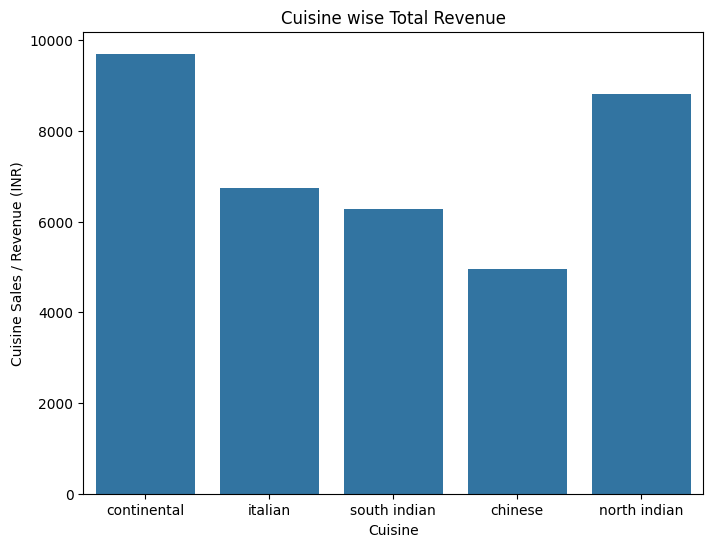

In [155]:


plt.figure(figsize=(8,6))
sns.barplot(
    data=restaurant_cleaned_data,
    x="Cuisine",
    y="Cuisine_Sales"
)

plt.xlabel("Cuisine")
plt.ylabel("Cuisine Sales / Revenue (INR)")
plt.title("Cuisine wise Total Revenue")
#plt.savefig("Most Selling Cuisine")
plt.show()



## 2. Finding the Restaurant with good revenue


In [130]:
restaurant_cleaned_data["restaurant_sales"] = restaurant_cleaned_data.groupby("Restaurant_name")["Total_amount"].transform(sum)

restaurant_cleaned_data[["Restaurant_name","restaurant_sales"]]

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/1476897239.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  restaurant_cleaned_data["restaurant_sales"] = restaurant_cleaned_data.groupby("Restaurant_name")["Total_amount"].transform(sum)


,Restaurant_name,restaurant_sales
0,dindigul thalappakatti,4500.0
1,kfc,4460.0
2,anand bhavan,7190.0
3,domino's,7970.0
4,dindigul thalappakatti,4500.0
...,...,...
95,hotel saravana,7400.0
96,hotel saravana,7400.0
97,anand bhavan,7190.0
98,sangeetha,4990.0


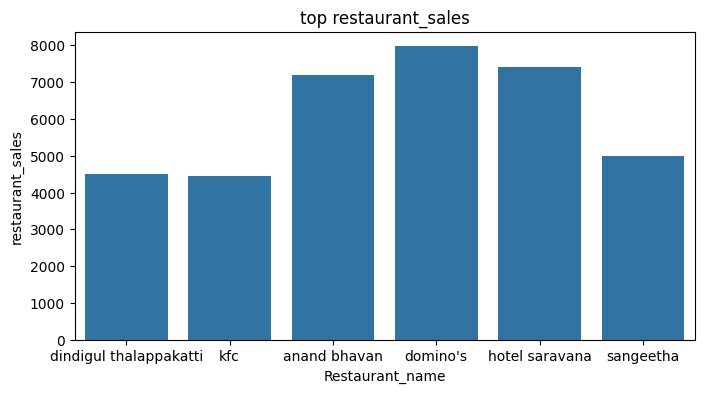

In [156]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=restaurant_cleaned_data,
    x="Restaurant_name",
    y="restaurant_sales"
)

plt.xlabel("Restaurant_name")
plt.ylabel("restaurant_sales")
plt.title("top restaurant_sales")
#plt.savefig("Restaurant with Good revenue")
plt.show()



In [140]:
print(restaurant_cleaned_data[["Restaurant_name","restaurant_sales"]].head())

          Restaurant_name  restaurant_sales
0  dindigul thalappakatti            4500.0
1                     kfc            4460.0
2            anand bhavan            7190.0
3                domino's            7970.0
4  dindigul thalappakatti            4500.0


## 3. Best city for Restaurant sales

/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/2358158550.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  restaurant_cleaned_data["city_sales"] = restaurant_cleaned_data.groupby("City")["Total_amount"].transform(sum)
/var/folders/3d/3gxgbbgx1zvgrj3gcsfz2f9m0000gn/T/ipykernel_1752/2358158550.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=restaurant_cleaned_data,x="City",y="city_sales", palette="mako")


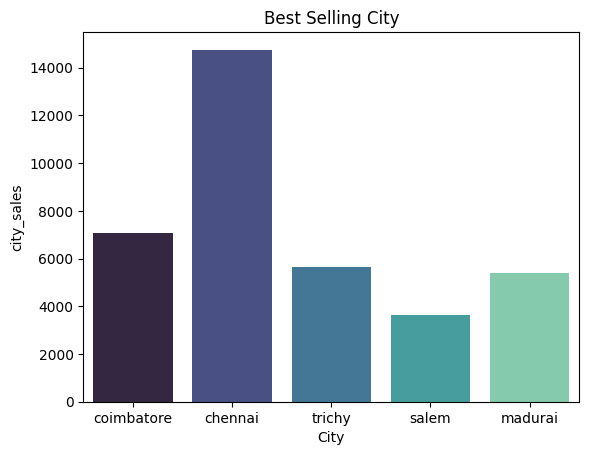

In [157]:
restaurant_cleaned_data["city_sales"] = restaurant_cleaned_data.groupby("City")["Total_amount"].transform(sum)

sns.barplot(data=restaurant_cleaned_data,x="City",y="city_sales", palette="mako")
plt.title("Best Selling City")
plt.xlabel("City")
plt.ylabel("city_sales")
#plt.savefig("Top City in Restaurant sale")
plt.show()



In [141]:
print(restaurant_cleaned_data[["City","city_sales"]].head())

         City  city_sales
0  coimbatore      7060.0
1     chennai     14750.0
2      trichy      5660.0
3     chennai     14750.0
4     chennai     14750.0


## Insights


**According to above analysis of Restaurant sales dataset,we can see the Top Restaurant sales is in CHENNAI for Rs 14750.0 and the TOP selling Restaurant name is Domino's for Rs.7970.0 and The Top selling Cuisine is Continental cuisine with cuisine sale for Rs 9700.0**

                                              ***********END***********